# Simulação térmica do dissipador

**Luis Gustavo Campos — Fundamentos de Engenharia, CEUB**

O modelo considera um dissipador de alumínio com sete aletas e uma fonte de calor de 6 W. A comparação é feita para duas condições: sem ventilador e com ventilador.

**Observação:** Foram utilizadas ferramentas de IA para auxílio nos cálculos

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve

HEATSINK_WIDTH = 0.040
HEATSINK_DEPTH = 0.040
HEATSINK_HEIGHT = 0.020
BASE_THICKNESS = 0.004
FIN_THICKNESS = 0.002
FIN_COUNT = 7
FIN_CENTERS = np.linspace(0.004, 0.036, FIN_COUNT)
CONTACT_WIDTH = 0.014

HEAT_POWER = 6.0
AIR_TEMPERATURE = 35.0
ALUMINUM_CONDUCTIVITY = 200.0
THERMAL_PAD_THICKNESS = 0.0001
THERMAL_PAD_CONDUCTIVITY = 3.0
CHIP_THERMAL_RESISTANCE = 1.0
TEMPERATURE_LIMIT = 80.0

YOUNG_MODULUS = 69e9
THERMAL_EXPANSION_COEFFICIENT = 23.4e-6

thermal_pad_resistance = THERMAL_PAD_THICKNESS / (
    THERMAL_PAD_CONDUCTIVITY * CONTACT_WIDTH**2
)

In [ ]:
def create_geometry(cell_size):
    x_positions = (np.arange(round(HEATSINK_WIDTH / cell_size)) + 0.5) * cell_size
    y_positions = (np.arange(round(HEATSINK_HEIGHT / cell_size)) + 0.5) * cell_size

    solid = np.broadcast_to(
        y_positions[:, None] < BASE_THICKNESS,
        (len(y_positions), len(x_positions)),
    ).copy()

    for center in FIN_CENTERS:
        solid |= (
            (y_positions[:, None] >= BASE_THICKNESS)
            & (np.abs(x_positions[None, :] - center) < FIN_THICKNESS / 2)
        )

    return x_positions, solid


def calculate_temperature(convection_coefficient, cell_size=0.0005):
    x_positions, solid = create_geometry(cell_size)
    height, width = solid.shape
    solid_cells = np.argwhere(solid)
    cell_index = {tuple(cell): index for index, cell in enumerate(solid_cells)}

    matrix = lil_matrix((len(solid_cells), len(solid_cells)))
    heat_input = np.zeros(len(solid_cells))

    heated_area = np.abs(x_positions - HEATSINK_WIDTH / 2) < CONTACT_WIDTH / 2
    heated_cells = np.count_nonzero(heated_area & solid[0])

    conduction = ALUMINUM_CONDUCTIVITY * HEATSINK_DEPTH
    convection = (cell_size * HEATSINK_DEPTH) / (
        1 / convection_coefficient + cell_size / (2 * ALUMINUM_CONDUCTIVITY)
    )

    exposed_cells = []

    for index, (row, col) in enumerate(solid_cells):
        diagonal = 0.0

        for row_step, col_step in ((0, -1), (0, 1), (-1, 0), (1, 0)):
            next_row = row + row_step
            next_col = col + col_step

            inside = 0 <= next_row < height and 0 <= next_col < width
            if inside and solid[next_row, next_col]:
                matrix[index, cell_index[next_row, next_col]] -= conduction
                diagonal += conduction
            elif row == 0 and row_step == -1:
                if heated_area[col]:
                    heat_input[index] += HEAT_POWER / heated_cells
            else:
                diagonal += convection
                heat_input[index] += convection * AIR_TEMPERATURE
                exposed_cells.append(index)

        matrix[index, index] = diagonal

    cell_temperatures = spsolve(matrix.tocsr(), heat_input)
    temperature_map = np.full(solid.shape, np.nan)
    temperature_map[solid] = cell_temperatures

    base_temperature = float(np.max(temperature_map[0, heated_area]))
    chip_temperature = base_temperature + HEAT_POWER * (
        thermal_pad_resistance + CHIP_THERMAL_RESISTANCE
    )
    released_heat = sum(
        convection * (cell_temperatures[index] - AIR_TEMPERATURE)
        for index in exposed_cells
    )

    return {
        'temperature_map': temperature_map,
        'base_temperature': base_temperature,
        'chip_temperature': chip_temperature,
        'released_heat': released_heat,
    }

## Comparação das temperaturas

Os coeficientes de convecção são valores adotados para o exercício. Não foram obtidos por medição.

Sem ventilador: 111.63 °C
Com ventilador: 58.44 °C
Limite de projeto: 80 °C


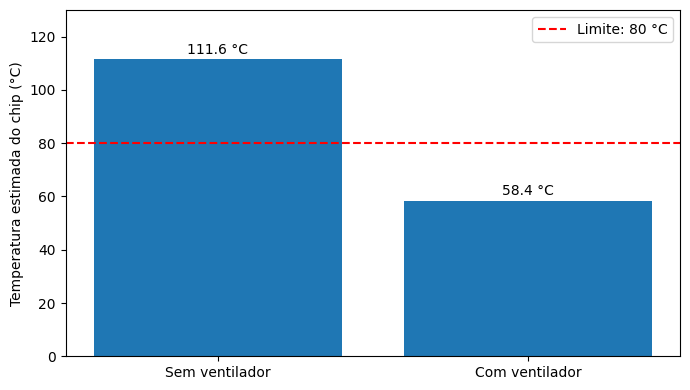

In [ ]:
passive_cooling = calculate_temperature(convection_coefficient=8)
active_cooling = calculate_temperature(convection_coefficient=35)

print(f'Sem ventilador: {passive_cooling["chip_temperature"]:.2f} °C')
print(f'Com ventilador: {active_cooling["chip_temperature"]:.2f} °C')
print(f'Limite de projeto: {TEMPERATURE_LIMIT:.0f} °C')

temperatures = [
    passive_cooling['chip_temperature'],
    active_cooling['chip_temperature'],
]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(['Sem ventilador', 'Com ventilador'], temperatures)
ax.axhline(TEMPERATURE_LIMIT, linestyle='--', color='red', label='Limite: 80 °C')

for index, temperature in enumerate(temperatures):
    ax.text(index, temperature + 2, f'{temperature:.1f} °C', ha='center')

ax.set_ylabel('Temperatura estimada do chip (°C)')
ax.set_ylim(0, 130)
ax.legend()
plt.tight_layout()
plt.show()

## Distribuição de temperatura

O mapa mostra a temperatura calculada no alumínio para o caso com ventilador.

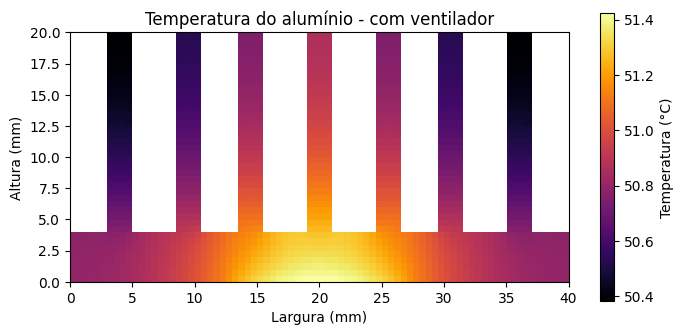

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.4))
heatmap = ax.imshow(
    np.ma.masked_invalid(active_cooling['temperature_map']),
    origin='lower',
    extent=[0, 40, 0, 20],
    aspect='equal',
    cmap='inferno',
)

ax.set_title('Temperatura do alumínio - com ventilador')
ax.set_xlabel('Largura (mm)')
ax.set_ylabel('Altura (mm)')
fig.colorbar(heatmap, ax=ax, label='Temperatura (°C)')
plt.tight_layout()
plt.show()

## Dilatação, tensão térmica e consumo

In [ ]:
temperature_change = active_cooling['base_temperature'] - AIR_TEMPERATURE
free_expansion_mm = THERMAL_EXPANSION_COEFFICIENT * 40 * temperature_change
thermal_stress_mpa = (
    YOUNG_MODULUS * THERMAL_EXPANSION_COEFFICIENT * temperature_change / 1e6
)
annual_energy_kwh = (2 * HEAT_POWER + 1) / 1000 * 24 * 365

print(f'Dilatação livre: {free_expansion_mm:.4f} mm')
print(f'Tensão teórica com dilatação impedida: {thermal_stress_mpa:.1f} MPa')
print(f'Consumo anual estimado (2 placas e ventilador): {annual_energy_kwh:.2f} kWh')

Dilatação livre: 0.0154 mm
Tensão teórica com dilatação impedida: 26.5 MPa
Consumo anual estimado (2 placas e ventilador): 113.88 kWh


**Observação:** a potência de 6 W por placa, a temperatura ambiente de 35 °C, os coeficientes de convecção e as resistências térmicas são hipóteses de cálculo. Os resultados representam uma estimativa, não um teste de temperatura em um Raspberry Pi real.